In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_curve, roc_auc_score,
    precision_recall_curve, average_precision_score
)

# 1. Data Understanding & EDA

Shape: (32561, 15)
Missing values:
 workclass         1836
occupation        1843
native.country     583
dtype: int64
Duplicates: 24


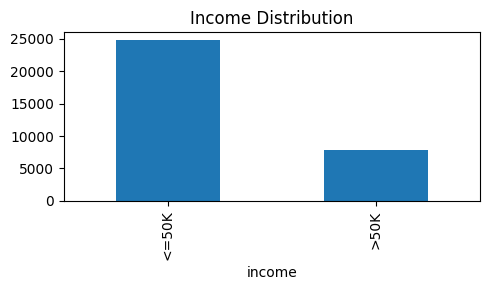

In [3]:
df = pd.read_csv("Adult Census Income.csv")
df = df.replace("?", np.nan)
print("Shape:", df.shape)
print("Missing values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Duplicates:", df.duplicated().sum())

plt.figure(figsize=(5, 3))
df["income"].value_counts().plot(kind="bar")
plt.title("Income Distribution")
plt.tight_layout()
plt.show()

# 2. Data Cleaning & Feature Engineering

In [5]:
df = df.drop_duplicates().dropna(subset=["income"]).copy()
df["target"] = df["income"].astype(str).str.contains(">50K").astype(int)
df["capital_net"] = df["capital.gain"] - df["capital.loss"]
df = df.drop(columns=["income", "education"])  # education.num already captures level

X = df.drop(columns=["target"])
y = df["target"]

# 3. Train/Test Split & Preprocessing

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = X.select_dtypes(include=[np.number]).columns.tolist()
cat_cols = X.select_dtypes(exclude=[np.number]).columns.tolist()

preprocessor = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("encoder", OneHotEncoder(handle_unknown="ignore"))]), cat_cols)
])

# 4. Models Comparison

In [7]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Naive Bayes": GaussianNB(),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=100, random_state=42)
}

In [ ]:
results = []
for name, clf in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", clf)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Accuracy": round(accuracy_score(y_test, y_pred), 4),
        "Precision": round(precision_score(y_test, y_pred, zero_division=0), 4),
        "Recall": round(recall_score(y_test, y_pred, zero_division=0), 4),
        "F1": round(f1_score(y_test, y_pred, zero_division=0), 4),
        "ROC-AUC": round(roc_auc_score(y_test, y_prob), 4),
        "PR-AUC": round(average_precision_score(y_test, y_prob), 4)
    })

comp_df = pd.DataFrame(results).sort_values(by="F1", ascending=False)
display(comp_df)

# 5. GridSearchCV on Best Model

In [ ]:
best_name = comp_df.iloc[0]["Model"]
best_f1_before = comp_df.iloc[0]["F1"]
param_grids = {
    "Random Forest": {"model__n_estimators": [100], "model__max_depth": [None, 12]},
    "Extra Trees": {"model__n_estimators": [100], "model__max_depth": [None, 12]},
    "Gradient Boosting": {"model__n_estimators": [100], "model__learning_rate": [0.1]},
    "Decision Tree": {"model__max_depth": [None, 10]},
    "KNN": {"model__n_neighbors": [5, 7]},
    "Logistic Regression": {"model__C": [1.0]},
    "SVM": {"model__C": [1.0]},
    "AdaBoost": {"model__n_estimators": [50, 100]},
    "Naive Bayes": {"model__var_smoothing": [1e-9]}
}

grid = GridSearchCV(
    Pipeline([("prep", preprocessor), ("model", models[best_name])]),
    param_grid=param_grids.get(best_name, {}),
    cv=3, scoring="f1", n_jobs=-1
)
grid.fit(X_train, y_train)
print("Best Model:", best_name)
print("best_params_:", grid.best_params_)
print("best_score_:", round(grid.best_score_, 4))

# 6. Final Evaluation & Plots

In [ ]:
best_model = grid.best_estimator_
y_pred_best = best_model.predict(X_test)
y_prob_best = best_model.predict_proba(X_test)[:, 1]
print(f"F1 Before Tuning: {best_f1_before:.4f} | After Tuning: {f1_score(y_test, y_pred_best, zero_division=0):.4f}")
print("\nClassification Report:\n", classification_report(y_test, y_pred_best))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_best), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_test, y_prob_best)
axes[1].plot(fpr, tpr, label=f"AUC={roc_auc_score(y_test, y_prob_best):.3f}")
axes[1].plot([0, 1], [0, 1], "k--")
axes[1].set_title("ROC Curve")
axes[1].legend()

prec_c, rec_c, _ = precision_recall_curve(y_test, y_prob_best)
axes[2].plot(rec_c, prec_c, label=f"AP={average_precision_score(y_test, y_prob_best):.3f}")
axes[2].set_title("Precision-Recall Curve")
axes[2].legend()
plt.tight_layout()
plt.show()